# CanGridT Testing

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

import matplotlib.ticker as mticker
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

import pymannkendall as mk

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
file_path = '../../../Data/CanGridT_V4/CanGridTmean_dlyV4_GNGA_2001_2024/tmean_CanGridTdlyV4_GNGA_2024.nc'
ds = xr.open_mfdataset(file_path)
ds

<xarray.Dataset> Size: 857MB
Dimensions:      (x: 621, y: 470, time: 365)
Coordinates:
  * x            (x) int32 2kB 1 2 3 4 5 6 7 8 ... 615 616 617 618 619 620 621
  * y            (y) int32 2kB 1 2 3 4 5 6 7 8 ... 464 465 466 467 468 469 470
  * time         (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-30
Data variables:
    lat          (x, y) float64 2MB dask.array<chunksize=(621, 470), meta=np.ndarray>
    lon          (x, y) float64 2MB dask.array<chunksize=(621, 470), meta=np.ndarray>
    temperature  (time, x, y) float64 852MB dask.array<chunksize=(365, 621, 470), meta=np.ndarray>
Attributes:
    title:        EASE-Grid with 2D lat/lon as curvilinear coordinates
    Conventions:  CF-1.6
    description:  Easy-grid NetCDF: every cell has its own lat/lon coordinates

In [6]:
ds.load()

<xarray.Dataset> Size: 857MB
Dimensions:      (x: 621, y: 470, time: 365)
Coordinates:
  * x            (x) int32 2kB 1 2 3 4 5 6 7 8 ... 615 616 617 618 619 620 621
  * y            (y) int32 2kB 1 2 3 4 5 6 7 8 ... 464 465 466 467 468 469 470
  * time         (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-30
Data variables:
    lat          (x, y) float64 2MB 71.38 71.36 71.33 ... 30.87 30.82 30.76
    lon          (x, y) float64 2MB 175.1 175.4 175.7 ... -70.17 -70.23 -70.28
    temperature  (time, x, y) float64 852MB nan nan nan nan ... nan nan nan nan
Attributes:
    title:        EASE-Grid with 2D lat/lon as curvilinear coordinates
    Conventions:  CF-1.6
    description:  Easy-grid NetCDF: every cell has its own lat/lon coordinates

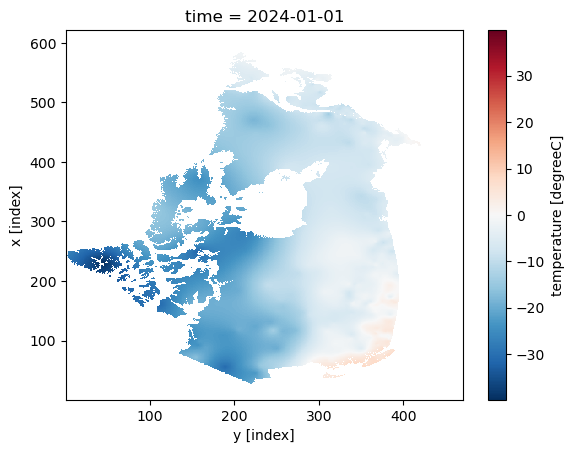

In [7]:
ds.sel(time='2024-01-01').temperature.plot()